# Classificação de gatos, cachorros e pandas — MLP + HOG + ANOVA F

Neste notebook, preservamos o mesmo dataset e a extração **HOG com 1.764 características** dos experimentos KNN/SVM. Agora, usamos **ANOVA F (`SelectKBest`)** para selecionar **50, 100 ou 200 características** e treinamos uma **MLP** em cada caso.


**Protocolo:** cada configuração é treinada somente com o conjunto de treino; a validação externa escolhe o melhor `k`; o teste é usado uma única vez para a avaliação final. Os resultados são calculados ao executar o notebook no Colab.


## 2. Desenho da arquitetura da rede

A representação é alterada **antes** da MLP:

```text
Imagem (64 × 64, tons de cinza)
       ↓
HOG: 1.764 características
       ↓
ANOVA F: selecionar as melhores k características (k = 50, 100 ou 200)
       ↓
StandardScaler (padronização)
       ↓
MLP: k entradas → 128 neurônios ReLU → 64 neurônios ReLU → 3 saídas
       ↓
Gato / Cachorro / Panda
```

**ANOVA F**, neste experimento, é apenas uma regra de ordenação: identifica quais posições do vetor HOG diferem mais entre as três classes, relativamente à variação dentro delas. **Não cria novas características.**

A seleção precisa ser ajustada **somente com o conjunto de treino**, para evitar vazamento de informação da validação ou do teste.


## 3. Importação das bibliotecas

As bibliotecas abaixo cuidam da leitura das imagens, extração HOG, organização dos dados, construção da rede neural e avaliação dos resultados.

In [1]:
# Path facilita a manipulação dos caminhos das pastas e dos arquivos.
from pathlib import Path

# NumPy organiza os vetores e matrizes numéricas.
import numpy as np

# Pandas organiza os caminhos, rótulos e conjuntos em uma tabela.
import pandas as pd

# Matplotlib e Seaborn são usados para gráficos e matriz de confusão.
import matplotlib.pyplot as plt
import seaborn as sns

# PIL abre e converte as imagens.
from PIL import Image

# HOG extrai características relacionadas aos contornos e gradientes da imagem.
from skimage.feature import hog

# LabelEncoder converte nomes de classes em códigos numéricos.
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Pipeline encadeia a padronização dos dados e o treinamento da rede.
from sklearn.pipeline import Pipeline

# ANOVA F calcula uma pontuação por característica; SelectKBest mantém as k melhores.
from sklearn.feature_selection import SelectKBest, f_classif

# MLPClassifier implementa uma rede neural do tipo perceptron multicamadas.
from sklearn.neural_network import MLPClassifier

# Métricas para avaliar a classificação.
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 4. Conectar o Google Drive e localizar o dataset

A pasta já está dividida em treino, validação e teste. **Não vamos selecionar imagens novamente nem criar outra divisão**, pois queremos preservar o mesmo conjunto usado nos experimentos com KNN e SVM.

In [2]:
# Esta importação funciona no Google Colab.
from google.colab import drive

# Monta o Google Drive no ambiente do Colab.
drive.mount('/content/drive')

# Ajuste este caminho somente se a pasta estiver em outro local do Drive.
PASTA_ORIGEM = Path('/content/drive/MyDrive/knnsvmtest_dividido')

# Os nomes devem corresponder exatamente às subpastas do dataset.
CLASSES = ['panda', 'dogs', 'cats']
CONJUNTOS = ['treino', 'validacao', 'teste']

# Extensões de imagem aceitas pelo código.
EXTENSOES = {
    '.jpg', '.jpeg', '.png', '.bmp',
    '.webp', '.jfif', '.tif', '.tiff'
}

# Confere se a pasta principal e todas as subpastas esperadas existem.
if not PASTA_ORIGEM.exists():
    raise FileNotFoundError(f'Pasta não encontrada: {PASTA_ORIGEM}')

for conjunto in CONJUNTOS:
    for classe in CLASSES:
        pasta = PASTA_ORIGEM / conjunto / classe
        if not pasta.exists():
            raise FileNotFoundError(f'Pasta esperada não encontrada: {pasta}')

print('Dataset localizado:', PASTA_ORIGEM)

Mounted at /content/drive
Dataset localizado: /content/drive/MyDrive/knnsvmtest_dividido


## 5. Criar a tabela de imagens e conferir a divisão

Cada linha da tabela representa uma imagem. O nome da pasta que contém a imagem fornece seu rótulo real; a pasta acima dela informa se a imagem pertence ao treino, à validação ou ao teste.

In [3]:
# Percorre as subpastas e coleta todos os arquivos que tenham extensão de imagem.
arquivos = sorted(
    p for p in PASTA_ORIGEM.rglob('*')
    if p.is_file() and p.suffix.lower() in EXTENSOES
)

# Cria uma tabela com o caminho do arquivo, sua classe e seu conjunto.
dados = pd.DataFrame({
    'caminho': [str(p) for p in arquivos],
    'classe': [p.parent.name for p in arquivos],
    'conjunto': [p.parent.parent.name for p in arquivos]
})

print('Total de imagens encontradas:', len(dados))
print('\\nQuantidade por classe e conjunto:')
display(pd.crosstab(dados['classe'], dados['conjunto']))

# Esta verificação corresponde à divisão preparada anteriormente:
# 1.050 imagens de treino, 225 de validação e 225 de teste.
# Se você tiver alterado o tamanho do dataset, ajuste esta checagem.
quantidades_esperadas = {'treino': 1050, 'validacao': 225, 'teste': 225}
quantidades_encontradas = dados['conjunto'].value_counts().to_dict()

if len(dados) != 1500 or quantidades_encontradas != quantidades_esperadas:
    raise ValueError(
        'A quantidade de imagens não corresponde à divisão esperada. '
        f'Encontrado: total={len(dados)}, conjuntos={quantidades_encontradas}. '
        'Confira a estrutura das pastas antes de continuar.'
    )

if set(dados['classe'].unique()) != set(CLASSES):
    raise ValueError('Os nomes das classes encontrados não correspondem aos esperados.')

print('\\nConferência concluída: dataset com divisão esperada.')

Total de imagens encontradas: 1500
\nQuantidade por classe e conjunto:


conjunto,teste,treino,validacao
classe,,,
cats,75,350,75
dogs,75,350,75
panda,75,350,75


\nConferência concluída: dataset com divisão esperada.


## 6. Visualizar a distribuição e algumas imagens

Antes de treinar, é útil conferir se as classes estão equilibradas e se as imagens parecem estar corretas. Problemas de organização, imagens corrompidas ou classes trocadas podem afetar o experimento.

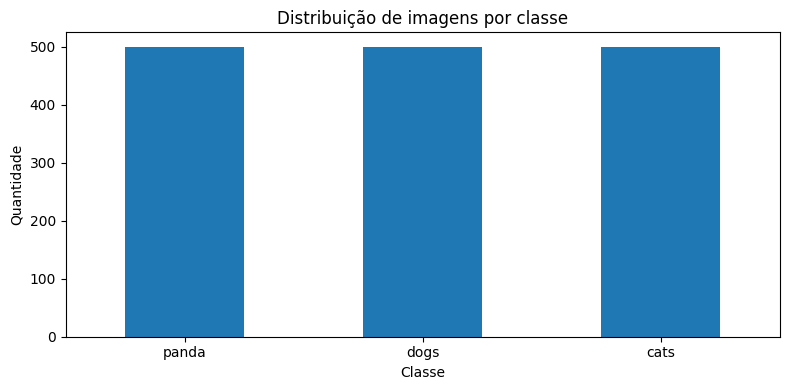

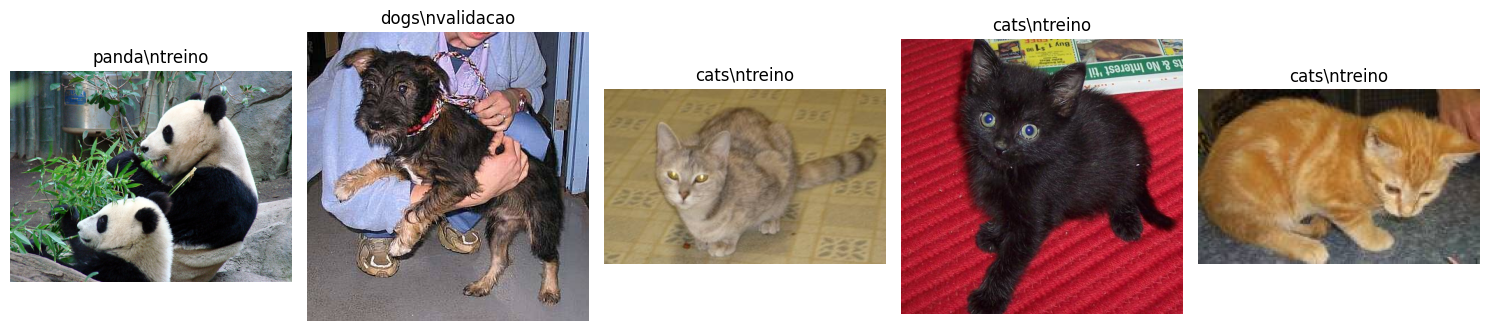

In [4]:
# Gráfico com a quantidade de imagens por classe.
plt.figure(figsize=(8, 4))
dados['classe'].value_counts().reindex(CLASSES).plot(kind='bar')
plt.title('Distribuição de imagens por classe')
plt.xlabel('Classe')
plt.ylabel('Quantidade')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Exibe até cinco imagens aleatórias para inspeção visual.
amostra = dados.sample(n=min(5, len(dados)), random_state=42)
fig, eixos = plt.subplots(1, len(amostra), figsize=(15, 4))

# Uniformiza o formato dos eixos quando há apenas uma imagem.
if len(amostra) == 1:
    eixos = [eixos]

for eixo, (_, linha) in zip(eixos, amostra.iterrows()):
    imagem = Image.open(linha['caminho']).convert('RGB')
    eixo.imshow(imagem)
    eixo.set_title(f"{linha['classe']}\\n{linha['conjunto']}")
    eixo.axis('off')

plt.tight_layout()
plt.show()

## 7. Visualização esquemática da MLP

A camada de entrada muda conforme o experimento: **300, 400 ou 500 valores**. As duas camadas ocultas permanecem iguais (128 e 64 neurônios), e a camada de saída tem 3 neurônios. O desenho representa poucos neurônios para não ficar ilegível.


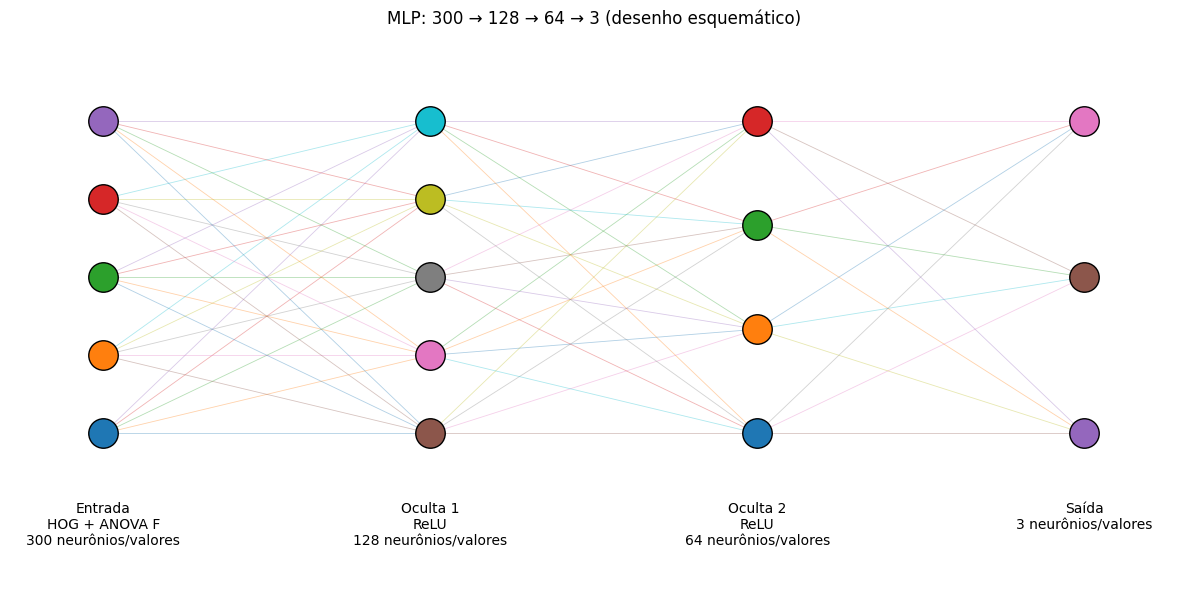

In [5]:
# Altere este valor para visualizar outra arquitetura.
K_DIAGRAMA = 300  # 300, 400 ou 500
assert K_DIAGRAMA in (300, 400, 500)

camadas_visuais = [
    {'nome': 'Entrada\nHOG + ANOVA F', 'qtd_real': K_DIAGRAMA, 'qtd_desenhada': 5},
    {'nome': 'Oculta 1\nReLU', 'qtd_real': 128, 'qtd_desenhada': 5},
    {'nome': 'Oculta 2\nReLU', 'qtd_real': 64, 'qtd_desenhada': 4},
    {'nome': 'Saída', 'qtd_real': 3, 'qtd_desenhada': 3}
]

fig, ax = plt.subplots(figsize=(12, 6))
x_posicoes = np.linspace(0.08, 0.92, len(camadas_visuais))
coordenadas = []
for x, camada in zip(x_posicoes, camadas_visuais):
    ys = np.linspace(0.18, 0.82, camada['qtd_desenhada'])
    coordenadas.append([(x, y) for y in ys])
for i in range(len(coordenadas) - 1):
    for x1, y1 in coordenadas[i]:
        for x2, y2 in coordenadas[i + 1]:
            ax.plot([x1, x2], [y1, y2], linewidth=0.6, alpha=0.35)
for x, camada, pontos in zip(x_posicoes, camadas_visuais, coordenadas):
    for px, py in pontos:
        ax.scatter(px, py, s=450, edgecolors='black', zorder=3)
    ax.text(x, 0.04, f"{camada['nome']}\n{camada['qtd_real']} neurônios/valores",
            ha='center', va='top', fontsize=10)
ax.set_title(f'MLP: {K_DIAGRAMA} → 128 → 64 → 3 (desenho esquemático)')
ax.set_xlim(0, 1)
ax.set_ylim(-0.12, 1)
ax.axis('off')
plt.tight_layout()
plt.show()


## 8. Extrair as características HOG

Nesta experiência, a rede neural não recebe diretamente os 64 × 64 pixels. Primeiro, usamos HOG para transformar cada imagem em um vetor de características que descreve padrões de gradientes e contornos. Assim, a MLP aprende a relacionar esses vetores às classes dos animais.

Isso permite comparar o classificador MLP com KNN e SVM usando a mesma representação visual. Em uma experiência futura, podemos substituir HOG por pixels normalizados ou por características aprendidas por uma rede convolucional.

In [6]:
def extrair_hog(caminho):
    # Abre a imagem e converte para tons de cinza.
    imagem = Image.open(caminho).convert('L')

    # Todas as imagens precisam ter o mesmo tamanho para gerar vetores compatíveis.
    imagem = imagem.resize((64, 64))

    # Converte a imagem em uma matriz NumPy de intensidades.
    imagem = np.array(imagem)

    # Calcula o vetor HOG com os mesmos parâmetros do experimento KNN/SVM.
    vetor = hog(
        imagem,
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm='L2-Hys'
    )

    return vetor

# Extrai HOG para todas as imagens. O processo pode levar alguns minutos.
# A extração é determinística: a mesma imagem e os mesmos parâmetros produzem
# o mesmo vetor. Não usamos os rótulos nesta etapa de extração.
lista_hog = []

for i, caminho in enumerate(dados['caminho']):
    lista_hog.append(extrair_hog(caminho))

    if (i + 1) % 100 == 0:
        print(f'Características extraídas: {i + 1}/{len(dados)}')

# Matriz X: uma linha por imagem e uma coluna por característica HOG.
X = np.array(lista_hog)

print('Formato da matriz HOG:', X.shape)
print('Número de características por imagem:', X.shape[1])

# Com a configuração HOG deste notebook, espera-se um vetor de 1.764 valores.
if X.shape[1] != 1764:
    print('Atenção: a dimensão HOG não é 1764. Confira os parâmetros de HOG e redimensionamento.')

Características extraídas: 100/1500
Características extraídas: 200/1500
Características extraídas: 300/1500
Características extraídas: 400/1500
Características extraídas: 500/1500
Características extraídas: 600/1500
Características extraídas: 700/1500
Características extraídas: 800/1500
Características extraídas: 900/1500
Características extraídas: 1000/1500
Características extraídas: 1100/1500
Características extraídas: 1200/1500
Características extraídas: 1300/1500
Características extraídas: 1400/1500
Características extraídas: 1500/1500
Formato da matriz HOG: (1500, 1764)
Número de características por imagem: 1764


## 9. Codificar as classes e separar treino, validação e teste

A rede aprende a prever um código para cada classe. O `LabelEncoder` transforma os nomes `cats`, `dogs` e `panda` em inteiros e permite recuperar os nomes após a previsão.

A divisão dos dados é feita a partir das pastas existentes. Não fazemos uma nova divisão aleatória, pois o objetivo é usar os mesmos conjuntos já usados nos experimentos anteriores.

In [7]:
# Recupera os rótulos textuais na mesma ordem em que as imagens foram processadas.
y_texto = dados['classe'].to_numpy()

# Ajusta o codificador às classes e transforma os nomes em números inteiros.
codificador = LabelEncoder()
y = codificador.fit_transform(y_texto)

print('Mapeamento das classes:')
for codigo, nome in enumerate(codificador.classes_):
    print(f'{codigo} -> {nome}')

# Seleciona os índices de cada conjunto com base na tabela de imagens.
idx_treino = dados.index[dados['conjunto'] == 'treino'].to_numpy()
idx_validacao = dados.index[dados['conjunto'] == 'validacao'].to_numpy()
idx_teste = dados.index[dados['conjunto'] == 'teste'].to_numpy()

# Seleciona as características e os rótulos correspondentes.
X_treino, y_treino = X[idx_treino], y[idx_treino]
X_validacao, y_validacao = X[idx_validacao], y[idx_validacao]
X_teste, y_teste = X[idx_teste], y[idx_teste]

print('\\nTamanhos dos conjuntos:')
print('Treino:', X_treino.shape, y_treino.shape)
print('Validação:', X_validacao.shape, y_validacao.shape)
print('Teste:', X_teste.shape, y_teste.shape)

Mapeamento das classes:
0 -> cats
1 -> dogs
2 -> panda
\nTamanhos dos conjuntos:
Treino: (1050, 1764) (1050,)
Validação: (225, 1764) (225,)
Teste: (225, 1764) (225,)


## 10. Treinar três redes MLP: 300, 400 e 500 características

Vamos comparar **três redes com a mesma configuração**, mudando somente a quantidade de características de entrada. O `Pipeline` executa as operações nesta ordem:

1. **ANOVA F (`SelectKBest`)**: calcula as pontuações a partir de `X_treino` e `y_treino` e mantém as `k` melhores características HOG.
2. **`StandardScaler`**: padroniza as características selecionadas.
3. **`MLPClassifier`**: aprende os pesos da rede neural com duas camadas ocultas de **128 e 64 neurônios**, usando ReLU e Adam.

A MLP conserva os hiperparâmetros do notebook original (`max_iter=300`, `batch_size=32`, `early_stopping=True`, `random_state=42` etc.). O `early_stopping` reserva **10% do conjunto de treino para monitoramento interno**, diferente das 225 imagens da validação externa. A seleção ANOVA F é ajustada ao conjunto de treino fornecido ao `Pipeline`; por isso, esse monitoramento interno não é uma validação totalmente independente da seleção de características, mas **não utiliza a validação externa nem o teste**.

**Critério de escolha:** maior acurácia na validação externa; em empate, maior F1 macro e, persistindo o empate, menor `k`.


In [8]:
# ============================================================
# MLP + HOG + ANOVA F: EXPERIMENTOS COM 50, 100 E 200 FEATURES
# ============================================================

VALORES_K = [50, 100, 200]

# Guardaremos cada rede já treinada, para não precisar repetir o treino.
modelos = {}
resultados = []

for k in VALORES_K:
    print('\n' + '=' * 65)
    print(f'EXPERIMENTO: MLP com {k} características HOG selecionadas por ANOVA F')
    print('=' * 65)

    # A seleção vem ANTES da padronização e da MLP.
    # O SelectKBest usa f_classif para atribuir uma pontuação ANOVA F
    # a cada uma das 1.764 características HOG.
    modelo_experimento = Pipeline([
        ('selecao', SelectKBest(score_func=f_classif, k=k)),
        ('scaler', StandardScaler()),
        ('mlp', MLPClassifier(
            hidden_layer_sizes=(128, 64),  # Duas camadas ocultas fixas
            activation='relu',             # Ativação nas camadas ocultas
            solver='adam',
            alpha=0.0001,
            batch_size=32,
            learning_rate_init=0.001,
            max_iter=300,
            early_stopping=True,
            validation_fraction=0.1,
            n_iter_no_change=15,
            random_state=42,
            verbose=False  # Evita imprimir centenas de linhas no Colab
        ))
    ])

    # O fit ajusta a seleção ANOVA, o scaler e os pesos da MLP
    # exclusivamente com os exemplos de TREINO.
    modelo_experimento.fit(X_treino, y_treino)

    # O pipeline reaplica a mesma seleção e padronização à validação.
    y_pred_val = modelo_experimento.predict(X_validacao)

    acuracia_val = accuracy_score(y_validacao, y_pred_val)
    precisao_val = precision_score(y_validacao, y_pred_val, average='macro', zero_division=0)
    recall_val = recall_score(y_validacao, y_pred_val, average='macro', zero_division=0)
    f1_val = f1_score(y_validacao, y_pred_val, average='macro', zero_division=0)

    modelos[k] = modelo_experimento
    resultados.append({
        'k': k,
        'acuracia_validacao': acuracia_val,
        'precisao_macro': precisao_val,
        'recall_macro': recall_val,
        'f1_macro': f1_val,
        'iteracoes': modelo_experimento.named_steps['mlp'].n_iter_
    })

    print(f'Características HOG originais: {X_treino.shape[1]}')
    print(f'Características selecionadas: {k}')
    print(f'Acurácia (validação): {acuracia_val:.4f}')
    print(f'F1 macro (validação): {f1_val:.4f}')

# Tabela comparativa ordenada pelo número de características.
tabela_resultados = pd.DataFrame(resultados).sort_values('k').reset_index(drop=True)
print('\nCOMPARAÇÃO DOS TRÊS EXPERIMENTOS — VALIDAÇÃO')
print(tabela_resultados.to_string(index=False, float_format=lambda x: f'{x:.4f}'))

# Escolhe a melhor configuração SEM olhar o conjunto de teste.
ranking = tabela_resultados.sort_values(
    ['acuracia_validacao', 'f1_macro', 'k'],
    ascending=[False, False, True]
)
melhor_k = int(ranking.iloc[0]['k'])
modelo = modelos[melhor_k]  # Nome mantido para as próximas células.
mlp_treinado = modelo.named_steps['mlp']

print(f'\nMELHOR CONFIGURAÇÃO: MLP com k={melhor_k}')
print(f'Acurácia na validação: {ranking.iloc[0]["acuracia_validacao"]:.4f}')
print(f'F1 macro na validação: {ranking.iloc[0]["f1_macro"]:.4f}')
print('Índices HOG escolhidos pela ANOVA F:')
print(modelo.named_steps['selecao'].get_support(indices=True))



EXPERIMENTO: MLP com 50 características HOG selecionadas por ANOVA F
Características HOG originais: 1764
Características selecionadas: 50
Acurácia (validação): 0.5600
F1 macro (validação): 0.5577

EXPERIMENTO: MLP com 100 características HOG selecionadas por ANOVA F
Características HOG originais: 1764
Características selecionadas: 100
Acurácia (validação): 0.5644
F1 macro (validação): 0.5631

EXPERIMENTO: MLP com 200 características HOG selecionadas por ANOVA F
Características HOG originais: 1764
Características selecionadas: 200
Acurácia (validação): 0.5867
F1 macro (validação): 0.5871

COMPARAÇÃO DOS TRÊS EXPERIMENTOS — VALIDAÇÃO
  k  acuracia_validacao  precisao_macro  recall_macro  f1_macro  iteracoes
 50              0.5600          0.5647        0.5600    0.5577         20
100              0.5644          0.5627        0.5644    0.5631         17
200              0.5867          0.5881        0.5867    0.5871         21

MELHOR CONFIGURAÇÃO: MLP com k=200
Acurácia na validação: 

## 11. Comparar o desempenho e visualizar a curva de aprendizado

Primeiro, veremos **acurácia e F1 macro** dos três tamanhos de vetor no conjunto de validação. Depois, visualizaremos a **curva de perda** da MLP selecionada. A curva de perda não é a acurácia: ela mostra o comportamento do erro otimizado durante o treinamento.


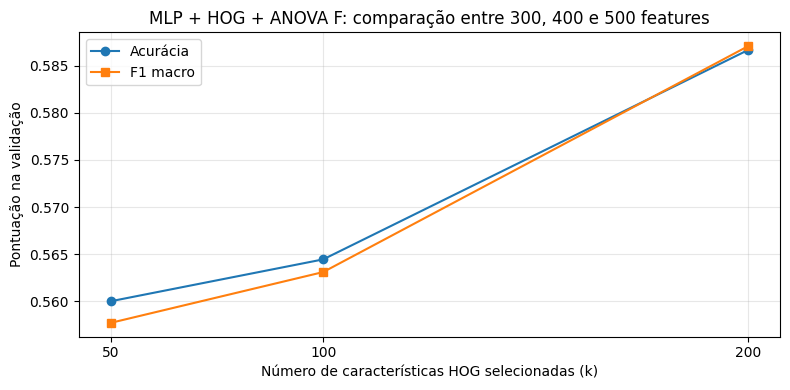

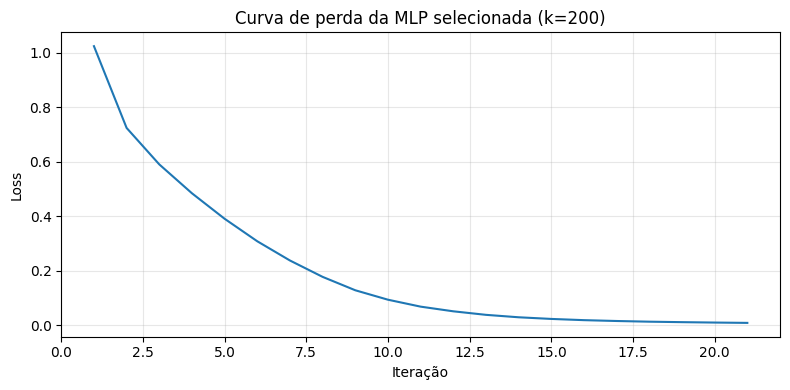

In [9]:
# Gráfico comparativo das três configurações, usando somente VALIDAÇÃO.
plt.figure(figsize=(8, 4))
plt.plot(tabela_resultados['k'], tabela_resultados['acuracia_validacao'],
         marker='o', label='Acurácia')
plt.plot(tabela_resultados['k'], tabela_resultados['f1_macro'],
         marker='s', label='F1 macro')
plt.xticks(VALORES_K)
plt.xlabel('Número de características HOG selecionadas (k)')
plt.ylabel('Pontuação na validação')
plt.title('MLP + HOG + ANOVA F: comparação entre 300, 400 e 500 features')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Curva de perda do modelo escolhido pela validação.
mlp_treinado = modelo.named_steps['mlp']
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(mlp_treinado.loss_curve_) + 1), mlp_treinado.loss_curve_)
plt.title(f'Curva de perda da MLP selecionada (k={melhor_k})')
plt.xlabel('Iteração')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 12. Resultado do modelo escolhido na validação

As três configurações já foram avaliadas na célula de treinamento. Agora exibimos as métricas do **melhor modelo**, selecionado sem consultar o conjunto de teste.


In [10]:
# O modelo é a configuração selecionada a partir dos três valores de k.
y_pred_validacao = modelo.predict(X_validacao)

print(f'RESULTADOS NA VALIDAÇÃO — MLP + HOG + ANOVA F (k={melhor_k})')
print(f'Acurácia:       {accuracy_score(y_validacao, y_pred_validacao):.4f}')
print(f'Precisão macro: {precision_score(y_validacao, y_pred_validacao, average="macro", zero_division=0):.4f}')
print(f'Recall macro:   {recall_score(y_validacao, y_pred_validacao, average="macro", zero_division=0):.4f}')
print(f'F1-score macro:{f1_score(y_validacao, y_pred_validacao, average="macro", zero_division=0):.4f}')


RESULTADOS NA VALIDAÇÃO — MLP + HOG + ANOVA F (k=200)
Acurácia:       0.5867
Precisão macro: 0.5881
Recall macro:   0.5867
F1-score macro:0.5871


## 13. Avaliação final no conjunto de teste

**Somente agora** usamos as imagens de teste. O modelo já foi escolhido pelos resultados de validação. O teste não deve ser utilizado para escolher outro valor de `k` ou ajustar hiperparâmetros.


In [11]:
# Gera as previsões finais para as imagens do conjunto de teste.
y_pred = modelo.predict(X_teste)

# Calcula as métricas globais.
acuracia = accuracy_score(y_teste, y_pred)
precisao = precision_score(y_teste, y_pred, average='macro', zero_division=0)
revocacao = recall_score(y_teste, y_pred, average='macro', zero_division=0)
f1 = f1_score(y_teste, y_pred, average='macro', zero_division=0)

print(f'RESULTADOS FINAIS — MLP + HOG + ANOVA F (k={melhor_k})')
print(f'Acurácia:      {acuracia:.4f}')
print(f'Precisão macro:{precisao:.4f}')
print(f'Recall macro:  {revocacao:.4f}')
print(f'F1-score macro:{f1:.4f}')

RESULTADOS FINAIS — MLP + HOG + ANOVA F (k=200)
Acurácia:      0.5689
Precisão macro:0.5685
Recall macro:  0.5689
F1-score macro:0.5606


## 14. Relatório de classificação por classe

O relatório detalha precisão, recall, F1-score e suporte para `cats`, `dogs` e `panda`. Isso é útil porque uma acurácia global pode esconder o fato de que o modelo reconhece bem uma classe, mas confunde outra com frequência.

In [12]:
# labels define a ordem dos códigos de classe; target_names mostra os nomes legíveis.
print(classification_report(
    y_teste,
    y_pred,
    labels=np.arange(len(codificador.classes_)),
    target_names=codificador.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

        cats       0.57      0.39      0.46        75
        dogs       0.52      0.60      0.56        75
       panda       0.61      0.72      0.66        75

    accuracy                           0.57       225
   macro avg       0.57      0.57      0.56       225
weighted avg       0.57      0.57      0.56       225



## 15. Matriz de confusão

As linhas representam as classes reais e as colunas representam as classes previstas. Os números da diagonal principal são acertos; os valores fora da diagonal mostram quais classes o modelo confundiu.

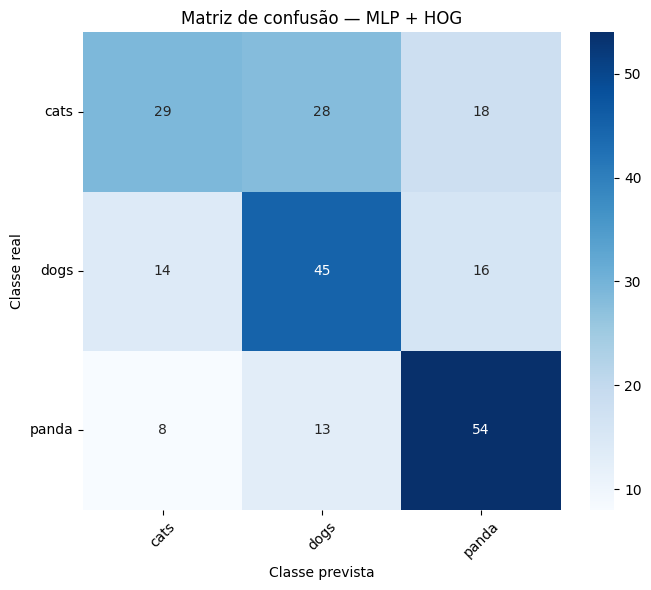

In [13]:
matriz = confusion_matrix(
    y_teste,
    y_pred,
    labels=np.arange(len(codificador.classes_))
)

plt.figure(figsize=(7, 6))
sns.heatmap(
    matriz,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=codificador.classes_,
    yticklabels=codificador.classes_
)
plt.title('Matriz de confusão — MLP + HOG')
plt.xlabel('Classe prevista')
plt.ylabel('Classe real')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## 16. Classificar uma imagem individual

Para uma imagem nova, não precisamos informar o rótulo verdadeiro: a rede faz uma previsão a partir das características da imagem. O rótulo real só é necessário se quisermos avaliar se a previsão está correta.

**Antes de executar a célula, altere `caminho_imagem` para o caminho real de uma imagem existente no seu Drive.**

Classe prevista: cats
\nProbabilidades estimadas por classe:
cats: 42.58%
dogs: 41.03%
panda: 16.39%


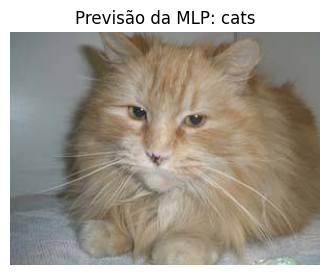

In [14]:
# Informe o caminho completo da imagem que deseja classificar.
caminho_imagem = '/content/drive/MyDrive/test_animals/cats/cats_00019.jpg'

# Confere se o arquivo informado existe antes de tentar abri-lo.
if not Path(caminho_imagem).exists():
    raise FileNotFoundError(
        f'Imagem não encontrada: {caminho_imagem}. '
        'Altere a variável caminho_imagem para um arquivo existente.'
    )

# Extrai as 1.764 características HOG originais.
# O Pipeline seleciona automaticamente as mesmas k características ANOVA F
# aprendidas no treinamento, antes de padronizar e classificar.
caracteristicas = extrair_hog(caminho_imagem)

# A rede espera uma matriz: linhas = imagens, colunas = características.
# reshape(1, -1) transforma o vetor único em uma matriz com uma linha.
caracteristicas = caracteristicas.reshape(1, -1)

# O modelo estima o código da classe para a imagem.
predicao = modelo.predict(caracteristicas)

# Converte o código numérico para o nome original da classe.
classe_predita = codificador.inverse_transform(predicao)[0]

# predict_proba retorna a probabilidade estimada para cada classe.
# Estas probabilidades são estimativas do modelo, não garantias de certeza.
probabilidades = modelo.predict_proba(caracteristicas)[0]

print('Classe prevista:', classe_predita)
print('\\nProbabilidades estimadas por classe:')
for nome_classe, probabilidade in zip(codificador.classes_, probabilidades):
    print(f'{nome_classe}: {probabilidade:.2%}')

# Exibe a imagem e a previsão para facilitar a interpretação.
imagem = Image.open(caminho_imagem).convert('RGB')
plt.figure(figsize=(4, 4))
plt.imshow(imagem)
plt.title(f'Previsão da MLP: {classe_predita}')
plt.axis('off')
plt.show()